# Analysis: Price per Pack by Customer Segment
This notebook starts from the processed data made in `01_Analysis.ipynb`.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

import sys
from pathlib import Path
sys.path.append(str(Path("../src").resolve()))

SEED = 556

In [3]:
df_cust = pd.read_csv("../data/processed/processed_data.csv", parse_dates=["DATE"])

assert len(df_cust) == 246739
assert df_cust["price_per_pack"].notna().all()
assert df_cust["LIFESTAGE"].notna().all()
print(df_cust.shape)

(246739, 13)


## Descriptive summaries

In [4]:
df_cust["price_per_pack"].describe()

count    246739.000000
mean          3.832419
std           1.077802
min           1.320000
25%           3.000000
50%           3.800000
75%           4.600000
max           6.500000
Name: price_per_pack, dtype: float64

In [5]:
seg = (
    df_cust.groupby(["LIFESTAGE", "PREMIUM_CUSTOMER"])
        .agg(
            cards=("LYLTY_CARD_NBR", "nunique"),
            packs=("PROD_QTY", "sum"),
            sales=("TOT_SALES", "sum"),
        )
)
seg["price_per_pack"] = seg["sales"] / seg["packs"]
seg.sort_values("price_per_pack", ascending=False).head(8).reset_index()

,LIFESTAGE,PREMIUM_CUSTOMER,cards,packs,sales,price_per_pack
0,YOUNG SINGLES/COUPLES,Mainstream,7917,36225,147582.20,4.074043
1,MIDAGE SINGLES/COUPLES,Mainstream,3298,21213,84734.25,3.994449
2,NEW FAMILIES,Mainstream,830,4060,15979.70,3.935887
3,RETIREES,Budget,4385,26932,105916.30,3.932731
4,NEW FAMILIES,Budget,1087,5241,20607.45,3.931969
5,RETIREES,Premium,3812,23266,91296.65,3.924037
6,OLDER SINGLES/COUPLES,Premium,4682,31693,123531.55,3.897755
7,OLDER SINGLES/COUPLES,Budget,4849,32883,127833.60,3.887529


In [6]:
print(df_cust["pack_g"].value_counts().sort_index())
print()
print(df_cust["brand"].value_counts().head(10))

pack_g
70.0      1507
90.0      3008
110.0    22387
125.0     1454
134.0    25102
135.0     3257
150.0    40203
160.0     2970
165.0    15297
170.0    19983
175.0    66389
180.0     1468
190.0     2995
200.0     4473
210.0     6272
220.0     1564
250.0     3169
270.0     6285
330.0    12540
380.0     6416
Name: count, dtype: int64

brand
KETTLE       41288
SMITHS       30352
DORITOS      25224
PRINGLES     25102
RRD          16321
INFUZIONS    14201
THINS        14075
WW           11836
COBS          9693
TOSTITOS      9471
Name: count, dtype: int64


**Pack sizes.** The most common pack size is 175g, which appears in 66,389
purchase lines, followed by 150g (40,203) and 134g (25,102). Pack sizes range
from 70g to 380g. Pack size could affect price per pack because larger packs
cost more. A customer segment could therefore show a higher average price per
pack simply by buying bigger packs, not by paying more for the same product.
This is one reason the results will be described as an association and not as
proof that the segment pays more for the same chips.

In [7]:
lifestage_order = [
    "YOUNG SINGLES/COUPLES", "MIDAGE SINGLES/COUPLES", "OLDER SINGLES/COUPLES",
    "NEW FAMILIES", "YOUNG FAMILIES", "OLDER FAMILIES", "RETIREES",
]
tier_order = ["Budget", "Mainstream", "Premium"]
tier_colors = ["#9ecae1", "#3182bd", "#08306b"]

sales = (
    df_cust.groupby(["LIFESTAGE", "PREMIUM_CUSTOMER"], as_index=False)["TOT_SALES"]
    .sum()
)
sales["sales_thousands"] = sales["TOT_SALES"] / 1000

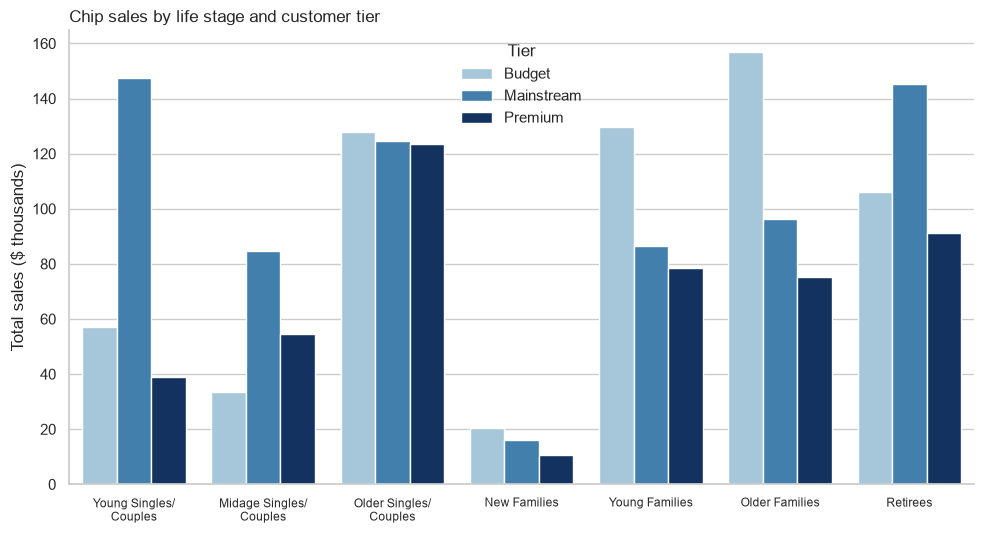

In [8]:
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(10, 5.5))
sns.barplot(
    data=sales, x="LIFESTAGE", y="sales_thousands",
    hue="PREMIUM_CUSTOMER", order=lifestage_order, hue_order=tier_order,
    palette=tier_colors, errorbar=None, ax=ax,
)
ax.set_xticks(range(len(lifestage_order)))
ax.set_xticklabels([s.title().replace("/", "/\n") for s in lifestage_order], fontsize=8.5)
ax.set_xlabel("")
ax.set_ylabel("Total sales ($ thousands)")
ax.set_title("Chip sales by life stage and customer tier", loc="left")
ax.legend(title="Tier", frameon=False)
sns.despine(ax=ax)
fig.tight_layout()

fig.savefig("../figures/01_sales_by_segment.png", dpi=200, bbox_inches="tight")
plt.show()

**Figure 1.** Young Singles/Couples (Mainstream), Older Families (Budget), and
Retirees (Mainstream) generate the most sales. Total sales depend on how many
customers a segment has as well as how much each spends, so this figure shows
where revenue comes from, not which segment pays more per pack.

Monthly sales

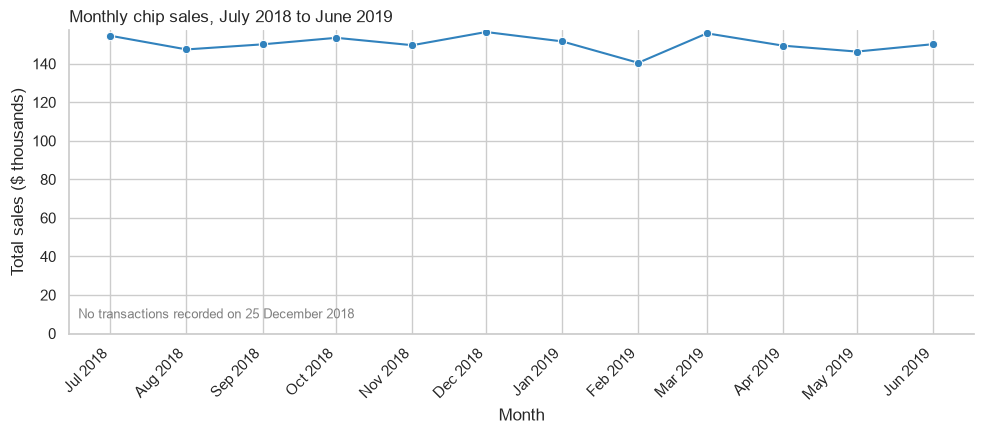

In [9]:
monthly = df_cust.set_index("DATE")["TOT_SALES"].resample("MS").sum() / 1000

sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.lineplot(x=monthly.index, y=monthly.values, marker="o", color="#3182bd", ax=ax)
ax.set_ylim(0)
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
ax.set_xlabel("Month")
ax.set_ylabel("Total sales ($ thousands)")
ax.set_title("Monthly chip sales, July 2018 to June 2019", loc="left")
ax.text(0.01, 0.05, "No transactions recorded on 25 December 2018",
        transform=ax.transAxes, fontsize=9, color="gray")
sns.despine(ax=ax)
fig.tight_layout()

fig.savefig("../figures/02_monthly_sales.png", dpi=200, bbox_inches="tight")
plt.show()

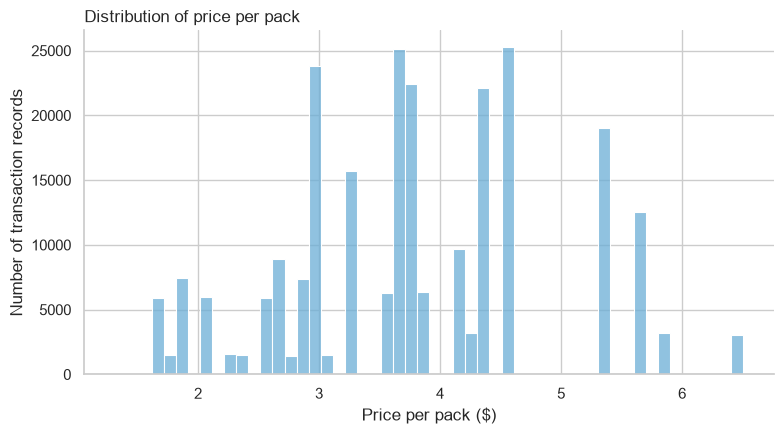

In [11]:
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(data=df_cust, x="price_per_pack", binwidth=0.1, color="#6baed6", ax=ax)
ax.set_xlabel("Price per pack ($)")
ax.set_ylabel("Number of transaction records")
ax.set_title("Distribution of price per pack", loc="left")
sns.despine(ax=ax)
fig.tight_layout()

fig.savefig("../figures/03_price_hist.png", dpi=200, bbox_inches="tight")
plt.show()